# Week 7 — Annotator Consistency (Signal vs. Noise)

Tests how much PluriHarms disagreement survives once inconsistent annotators are identified, following Ghafouri et al. (2026), *Position: RLHF May Not Reflect Genuine Preferences* (ICML 2026). Results feed Section 4.5 of the report.

1. **Framing consistency**: the 7 prompt pairs from their Appendix E (replicates 78/673 = 11.6%).
2. **Theme-level inconsistency ratio (IR)**: within-theme variance (dominant SafetyAnalyst action category) divided by a per-annotator permutation baseline. A reconstruction, not their exact procedure.
3. **Leave-one-out agreement**.
4. Filtering consequences vs. **random removal** of the same number of annotators.
5. Robustness of the Section 4.4 Mann–Whitney effects + annotator-level OLS (n = 100).
6. Order effects, response style, and base-model (A+D+E) predictability.

Run from the repo root. Requires `krippendorff` and `statsmodels`. Runtime about 2–3 minutes.

In [1]:
import os
os.makedirs('outputs', exist_ok=True)
# %pip install krippendorff statsmodels

## 1–4. Diagnostics and filtering

In [ ]:
import sys, json
import numpy as np, pandas as pd
from scipy.stats import mannwhitneyu, ttest_ind, pearsonr, spearmanr, linregress
import krippendorff

ROOT = '.'
a = pd.read_csv(f'PluriHarms-release\data\annotations.csv')
p = pd.read_csv(f'PluriHarms-release/data/prompts.csv')
QI = p['Question_Index'].values
R = a[[f'Rating_{q}' for q in QI]].values.astype(float)       # 100 x 150
T = a[[f'Trial_{q}' for q in QI]].values.astype(float)
nA, nP = R.shape
out = {}

# ---------- sanity: replicate report numbers ----------
std_p = np.nanstd(R, axis=0, ddof=1)
med_std = np.median(std_p)
contested = std_p > med_std
out['sanity'] = dict(mean_rating=np.nanmean(R), mean_std=std_p.mean(), median_std=med_std,
                     n_contested=int(contested.sum()))

# ---------- D1: framing pairs (Ghafouri et al. 2026, Table 15) ----------
# (A, B, type) ; 'eq' = equivalent, 'gt' = B expected more harmful than A
pairs = {'Nuclear reactor': (22, 23, 'eq'), 'Security research': (85, 86, 'eq'),
         'Goldman Sachs': (27, 31, 'eq'), 'Child grooming': (80, 41, 'gt'),
         'Animal abuse': (145, 146, 'gt'), 'Self-injury': (63, 66, 'gt'),
         'Student records': (65, 67, 'gt')}
col = {q: i for i, q in enumerate(QI)}
strong = np.zeros(nA); nobs = np.zeros(nA)
pair_rows = []
for name, (qa, qb, kind) in pairs.items():
    ra, rb = R[:, col[qa]], R[:, col[qb]]
    ok = ~np.isnan(ra) & ~np.isnan(rb)
    d = rb - ra
    if kind == 'eq':
        s = (np.abs(d) > 30) & ok
    else:
        s = (d < -15) & ok
    strong += s; nobs += ok
    pair_rows.append(dict(pair=name, A=qa, B=qb, kind=kind, n=int(ok.sum()),
                          mean_abs_diff=float(np.nanmean(np.abs(d[ok]))),
                          strong=int(s.sum())))
out['pairs'] = pair_rows
out['pairs_total'] = dict(n=int(nobs.sum()), strong=int(strong.sum()),
                          pct=float(strong.sum() / nobs.sum() * 100),
                          eq_strong=sum(r['strong'] for r in pair_rows if r['kind'] == 'eq'),
                          eq_n=sum(r['n'] for r in pair_rows if r['kind'] == 'eq'),
                          gt_strong=sum(r['strong'] for r in pair_rows if r['kind'] == 'gt'),
                          gt_n=sum(r['n'] for r in pair_rows if r['kind'] == 'gt'),
                          annot_with_any=int((strong > 0).sum()))

# ---------- D2: theme-level inconsistency ratio ----------
act = [c for c in p.columns if c.startswith('action_')]
theme = p[act].values.argmax(axis=1)
rng = np.random.default_rng(42)
NPERM = 2000
def within_var(r, th):
    ok = ~np.isnan(r); r, th = r[ok], th[ok]
    keep = np.isin(th, [t for t in np.unique(th) if (th == t).sum() >= 3])
    r, th = r[keep], th[keep]
    ss, k = 0.0, 0
    for t in np.unique(th):
        x = r[th == t]; ss += ((x - x.mean()) ** 2).sum(); k += 1
    return ss / (len(r) - k), r, th
IR = np.zeros(nA)
for i in range(nA):
    w, r, th = within_var(R[i], theme)
    perm = []
    for _ in range(NPERM):
        rp = rng.permutation(r)
        ss, k = 0.0, 0
        for t in np.unique(th):
            x = rp[th == t]; ss += ((x - x.mean()) ** 2).sum(); k += 1
        perm.append(ss / (len(rp) - k))
    IR[i] = w / np.mean(perm)
themes_used = [act[t].replace('action_', '') for t in np.unique(theme) if (theme == t).sum() >= 3]
out['IR'] = dict(themes=len(themes_used), mean=IR.mean(), median=np.median(IR), min=IR.min(), max=IR.max(),
                 share_ge_1=float((IR >= 1).mean()))

# ---------- D3: agreement with leave-one-out consensus ----------
loo = np.zeros(nA)
for i in range(nA):
    others = np.nanmean(np.delete(R, i, axis=0), axis=0)
    ok = ~np.isnan(R[i]); loo[i] = pearsonr(R[i][ok], others[ok])[0]
out['loo'] = dict(mean=loo.mean(), min=loo.min(), max=loo.max(), n_below_03=int((loo < 0.3).sum()))

meanr = np.nanmean(R, axis=1)
out['convergent'] = dict(
    IR_vs_loo=spearmanr(IR, loo)[0], IR_vs_pairstrong=spearmanr(IR, strong)[0],
    loo_vs_pairstrong=spearmanr(loo, strong)[0])

# ---------- directional bias ----------
hi = IR > np.median(IR)
t, pv = ttest_ind(meanr[~hi], meanr[hi])
out['direction'] = dict(r_IR_mean=pearsonr(IR, meanr)[0], p_r=pearsonr(IR, meanr)[1],
                        mean_consistent=meanr[~hi].mean(), mean_inconsistent=meanr[hi].mean(),
                        diff=meanr[~hi].mean() - meanr[hi].mean(), t=t, p=pv,
                        r_loo_mean=pearsonr(loo, meanr)[0],
                        r_pairs_mean=pearsonr(strong, meanr)[0])

# ---------- filtering consequences ----------
def harmful(M):
    above = (M > 50).sum(0); n = (~np.isnan(M)).sum(0)
    return above / n > 0.5
base_lab = harmful(R); base_mean = np.nanmean(R, 0)
def consequences(keep):
    M = R[keep]
    lab = harmful(M); mu = np.nanmean(M, 0)
    return dict(flip_pct=float((lab != base_lab).mean() * 100), n_flip=int((lab != base_lab).sum()),
                mean_abs_shift=float(np.abs(mu - base_mean).mean()),
                max_abs_shift=float(np.abs(mu - base_mean).max()),
                signed_shift=float((mu - base_mean).mean()),
                mean_std=float(np.nanstd(M, 0, ddof=1).mean()),
                contested_std=float(np.nanstd(M[:, contested], 0, ddof=1).mean()),
                uncontested_std=float(np.nanstd(M[:, ~contested], 0, ddof=1).mean()),
                alpha=float(krippendorff.alpha(reliability_data=M, level_of_measurement='interval')))
def random_baseline(k, n=2000):
    res = [consequences(np.isin(np.arange(nA), rng.choice(nA, k, replace=False))) for _ in range(n)]
    df = pd.DataFrame(res)
    return {c: (float(df[c].mean()), float(df[c].quantile(.025)), float(df[c].quantile(.975))) for c in
            ['flip_pct', 'mean_abs_shift', 'signed_shift', 'mean_std', 'contested_std', 'alpha']} | \
           {'p_flip_ge': None}, df
full = consequences(np.ones(nA, bool))
out['full'] = full
order = np.argsort(IR)  # most consistent first
filt = {}
for label, k in [('drop_top50pct', 50), ('drop_top20pct', 80)]:
    keep = np.zeros(nA, bool); keep[order[:k]] = True
    c = consequences(keep)
    rb, df = random_baseline(k, 1000)
    rb['p_flip_ge'] = float((df['flip_pct'] >= c['flip_pct']).mean())
    rb['p_signed_ge'] = float((df['signed_shift'].abs() >= abs(c['signed_shift'])).mean())
    filt[label] = dict(filtered=c, random=rb)
# also only-inconsistent half (mirror)
keep = np.zeros(nA, bool); keep[order[50:]] = True
filt['keep_only_inconsistent_half'] = dict(filtered=consequences(keep))
out['filter'] = filt
keep_c = np.zeros(nA, bool); keep_c[order[:50]] = True   # consistent half

# ---------- robustness of Mann-Whitney findings ----------
long = []
for i in range(nA):
    for j in range(nP):
        if not np.isnan(R[i, j]):
            long.append((i, j, R[i, j], contested[j]))
L = pd.DataFrame(long, columns=['ann', 'pj', 'rating', 'contested'])
for c in ['Gender', 'Education', 'Factor_1', 'Race_Ethnicity']:
    L[c] = a[c].values[L['ann']]
L['consistent'] = keep_c[L['ann']]
low_ed = ['High school diploma or GED', 'Some college, but no degree', 'Associates or technical degree']
high_ed = ["Bachelor’s degree", 'Graduate or professional degree (MA, MS, MBA, PhD, JD, MD, DDS etc.)']
def tests(df):
    res = {}
    g1, g2 = df[df.Gender == 'Man'].rating, df[df.Gender == 'Woman'].rating
    res['Gender (Woman-Man)'] = (g2.mean() - g1.mean(), mannwhitneyu(g1, g2).pvalue)
    g1, g2 = df[df.Education.isin(low_ed)].rating, df[df.Education.isin(high_ed)].rating
    res['Education (High-Low)'] = (g2.mean() - g1.mean(), mannwhitneyu(g1, g2).pvalue)
    m = df['Factor_1'].median()
    g1, g2 = df[df.Factor_1 <= m].rating, df[df.Factor_1 > m].rating
    res['Factor 1 (Authority-Universalist)'] = (g2.mean() - g1.mean(), mannwhitneyu(g1, g2).pvalue)
    g1, g2 = df[df.Race_Ethnicity == 'White'].rating, df[(df.Race_Ethnicity != 'White') & df.Race_Ethnicity.notna()].rating
    res['Race (Non-white-White)'] = (g2.mean() - g1.mean(), mannwhitneyu(g1, g2).pvalue)
    return res
mw = {}
for nm, d in [('all_full', L), ('contested_full', L[L.contested]),
              ('all_consistent', L[L.consistent]), ('contested_consistent', L[L.consistent & L.contested])]:
    mw[nm] = tests(d)
out['mw'] = mw
# composition of inconsistent half
comp = {}
ed_hi = a.Education.isin(high_ed).values
comp['women_share_consistent'] = float((a.Gender.values[keep_c] == 'Woman').mean())
comp['women_share_inconsistent'] = float((a.Gender.values[~keep_c] == 'Woman').mean())
comp['highed_share_consistent'] = float(ed_hi[keep_c].mean())
comp['highed_share_inconsistent'] = float(ed_hi[~keep_c].mean())
comp['F1_mean_consistent'] = float(a.Factor_1.values[keep_c].mean())
comp['F1_mean_inconsistent'] = float(a.Factor_1.values[~keep_c].mean())
comp['r_IR_F1'] = pearsonr(IR, a.Factor_1.values)[0]
comp['r_IR_F1_p'] = pearsonr(IR, a.Factor_1.values)[1]
comp['women_IR'] = float(IR[a.Gender.values == 'Woman'].mean()); comp['men_IR'] = float(IR[a.Gender.values == 'Man'].mean())
comp['gender_IR_p'] = mannwhitneyu(IR[a.Gender.values == 'Woman'], IR[a.Gender.values == 'Man']).pvalue
comp['ed_IR_p'] = mannwhitneyu(IR[ed_hi], IR[a.Education.isin(low_ed).values]).pvalue
out['composition'] = comp

# ---------- order / fatigue ----------
cons = np.nanmean(R, 0)
dev, pos, rat = [], [], []
for i in range(nA):
    others = np.nanmean(np.delete(R, i, 0), 0)
    rank = pd.Series(T[i]).rank().values  # 1..150 display position
    for j in range(nP):
        if not np.isnan(R[i, j]):
            dev.append(abs(R[i, j] - others[j])); pos.append(rank[j]); rat.append(R[i, j])
dev, pos, rat = map(np.array, (dev, pos, rat))
lr = linregress(pos, dev); lr2 = linregress(pos, rat)
third = np.digitize(pos, [50.5, 100.5])
out['order'] = dict(slope_dev_per_100=lr.slope * 100, p_dev=lr.pvalue,
                    slope_rating_per_100=lr2.slope * 100, p_rating=lr2.pvalue,
                    dev_by_third=[float(dev[third == k].mean()) for k in range(3)],
                    rating_by_third=[float(rat[third == k].mean()) for k in range(3)])
# response style
extreme = np.array([np.mean(np.isin(R[i][~np.isnan(R[i])], [0, 100])) for i in range(nA)])
mid = np.array([np.mean(R[i][~np.isnan(R[i])] == 50) for i in range(nA)])
out['style'] = dict(extreme_mean=extreme.mean(), r_IR_extreme=spearmanr(IR, extreme)[0],
                    mid_mean=mid.mean(), r_IR_mid=spearmanr(IR, mid)[0])

np.save('outputs/IR.npy', IR); np.save('outputs/loo.npy', loo)
np.save('outputs/strong.npy', strong)
json.dump(out, open('outputs/consistency_results.json', 'w'), indent=1, default=float)
print(json.dumps(out, indent=1, default=lambda x: round(float(x), 4)))

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (460764662.py, line 7)

## 5–6. Robustness of Section 4.4 and model predictability

In [ ]:
import sys, json
import numpy as np, pandas as pd
from scipy.stats import mannwhitneyu
import statsmodels.formula.api as smf
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

ROOT = '.'
a = pd.read_csv(f'{ROOT}/data/annotations.csv'); p = pd.read_csv(f'{ROOT}/data/prompts.csv')
QI = p['Question_Index'].values
R = a[[f'Rating_{q}' for q in QI]].values.astype(float)
IR = np.load('outputs/IR.npy'); strong = np.load('outputs/strong.npy')
nA, nP = R.shape
std_p = np.nanstd(R, 0, ddof=1); contested = std_p > np.median(std_p)
order = np.argsort(IR); keep_c = np.zeros(nA, bool); keep_c[order[:50]] = True
out = {}

low_ed = ['High school diploma or GED', 'Some college, but no degree', 'Associates or technical degree']
high_ed = ["Bachelor’s degree", 'Graduate or professional degree (MA, MS, MBA, PhD, JD, MD, DDS etc.)']
nonwhite = ['Black or African American', 'Latino or Hispanic', 'East Asian', 'South Asian', 'Other',
            'East Asian,South Asian', 'Latino or Hispanic,White', 'Black or African American,White',
            'American Indian, Alaska Native, or']  # exact list used in AnnotatorAnalysis.ipynb

# race replication with the notebook's exact grouping, full vs consistent
rows = [(i, j, R[i, j]) for i in range(nA) for j in range(nP) if not np.isnan(R[i, j])]
L = pd.DataFrame(rows, columns=['ann', 'pj', 'rating'])
L['race'] = a.Race_Ethnicity.values[L.ann]; L['cont'] = contested[L.pj]; L['cons'] = keep_c[L.ann]
race = {}
for nm, d in [('all_full', L), ('contested_full', L[L.cont]), ('all_consistent', L[L.cons]),
              ('contested_consistent', L[L.cons & L.cont])]:
    g1, g2 = d[d.race == 'White'].rating, d[d.race.isin(nonwhite)].rating
    race[nm] = (g2.mean() - g1.mean(), mannwhitneyu(g1, g2).pvalue)
out['race'] = race

# annotator-level OLS (n=100): mean rating ~ group indicators + IR
A = pd.DataFrame({
    'mean_all': np.nanmean(R, 1), 'mean_cont': np.nanmean(R[:, contested], 1),
    'woman': (a.Gender == 'Woman').astype(float), 'highed': a.Education.isin(high_ed).astype(float),
    'F1': a.Factor_1.values, 'IR': (IR - IR.mean()) / IR.std(), 'pairs': strong})
A = A[a.Gender.isin(['Man', 'Woman']).values]
ols = {}
for y in ['mean_all', 'mean_cont']:
    for f in ['woman + highed + F1', 'woman + highed + F1 + IR']:
        m = smf.ols(f'{y} ~ {f}', A).fit()
        ols[f'{y} | {f}'] = {k: (m.params[k], m.pvalues[k]) for k in m.params.index if k != 'Intercept'} | {'R2': m.rsquared, 'n': int(m.nobs)}
out['ols'] = ols
out['n_gender_known'] = int(len(A))

# second filter: framing-pair based (drop annotators with >=1 strong inconsistency)
def harmful(M):
    return (M > 50).sum(0) / (~np.isnan(M)).sum(0) > 0.5
base = harmful(R)
kp = strong == 0
Mp = R[kp]
out['pair_filter'] = dict(kept=int(kp.sum()), flip_pct=float((harmful(Mp) != base).mean() * 100),
                          signed_shift=float((np.nanmean(Mp, 0) - np.nanmean(R, 0)).mean()),
                          mean_abs_shift=float(np.abs(np.nanmean(Mp, 0) - np.nanmean(R, 0)).mean()),
                          contested_std=float(np.nanstd(Mp[:, contested], 0, ddof=1).mean()),
                          uncontested_std=float(np.nanstd(Mp[:, ~contested], 0, ddof=1).mean()))
rng = np.random.default_rng(7)
rf = []
for _ in range(2000):
    k = np.zeros(nA, bool); k[rng.choice(nA, int(kp.sum()), replace=False)] = True
    rf.append((harmful(R[k]) != base).mean() * 100)
rf = np.array(rf)
out['pair_filter']['random_flip_mean'] = float(rf.mean())
out['pair_filter']['random_flip_ci'] = [float(np.quantile(rf, .025)), float(np.quantile(rf, .975))]
out['pair_filter']['p_flip_ge'] = float((rf >= out['pair_filter']['flip_pct']).mean())

# base model A+D+E (individual rating, prompt split) -- full vs consistent half vs random halves
act = [c for c in p.columns if c.startswith('action_')]; eff = [c for c in p.columns if c.startswith('effect_')]
cat_A = act + eff
cat_D = ['Gender', 'Age', 'Political_Affiliation', 'Education', 'Social_Media_Frequency', 'Toxicity_Experience',
         'Income', 'Religion_Importance', 'Race_Ethnicity', 'Sexual_Orientation']
cat_E = ['Factor_1', 'Factor_2', 'Factor_3']
long = L[['ann', 'pj', 'rating']].copy()
long['question_index'] = QI[long.pj]
PA = p.set_index('Question_Index')[cat_A]
long = long.join(PA, on='question_index')
for c in cat_D + cat_E: long[c] = a[c].values[long.ann]
enc = pd.get_dummies(long, columns=cat_D, drop_first=True)
enc = enc.fillna(enc.median(numeric_only=True))
Dcols = [c for c in enc.columns if any(c.startswith(d + '_') for d in cat_D)]
feats = cat_A + Dcols + cat_E
np.random.seed(42); allp = p['Question_Index'].values.copy(); np.random.shuffle(allp)
trp, tep = allp[:100], allp[100:]
def fit(mask):
    d = enc[mask]
    tr, te = d[d.question_index.isin(trp)], d[d.question_index.isin(tep)]
    m = Ridge(alpha=1.0).fit(tr[feats].astype(float), tr.rating)
    pr = m.predict(te[feats].astype(float))
    return r2_score(te.rating, pr), mean_absolute_error(te.rating, pr)
full = fit(np.ones(len(enc), bool))
cons = fit(keep_c[enc.ann.values])
incons = fit(~keep_c[enc.ann.values])
rr = []
for _ in range(200):
    k = np.zeros(nA, bool); k[rng.choice(nA, 50, replace=False)] = True
    rr.append(fit(k[enc.ann.values]))
rr = np.array(rr)
out['model'] = dict(full=full, consistent=cons, inconsistent=incons,
                    random_mean=rr.mean(0).tolist(), random_ci_r2=[float(np.quantile(rr[:, 0], .025)), float(np.quantile(rr[:, 0], .975))],
                    p_r2_ge=float((rr[:, 0] >= cons[0]).mean()))
json.dump(out, open('outputs/consistency_results2.json', 'w'), indent=1, default=float)
print(json.dumps(out, indent=1, default=lambda x: round(float(x), 4)))

{
 "race": {
  "all_full": [
   0.04227946183679876,
   0.2872314305247796
  ],
  "contested_full": [
   -1.8452385829401123,
   0.0026726758928893738
  ],
  "all_consistent": [
   -1.3248994701041,
   0.04120649764450889
  ],
  "contested_consistent": [
   -2.8439811409238445,
   0.0008012391266932865
  ]
 },
 "ols": {
  "mean_all | woman + highed + F1": {
   "woman": [
    4.519618151708654,
    0.11403851322468633
   ],
   "highed": [
    -3.6507439315389023,
    0.2131188001276647
   ],
   "F1": [
    -0.3665208484427849,
    0.36861642115974125
   ],
   "R2": 0.04832433116258328,
   "n": 100
  },
  "mean_all | woman + highed + F1 + IR": {
   "woman": [
    4.474584184655223,
    0.11826708544472735
   ],
   "highed": [
    -3.4393874530589077,
    0.24300762438034232
   ],
   "F1": [
    -0.20534214252978278,
    0.6481124139968315
   ],
   "IR": [
    -1.3209119811382108,
    0.398019326490989
   ],
   "R2": 0.05549056911160721,
   "n": 100
  },
  "mean_cont | woman + highed + F1

## Figure 5

5.333333333333334 3.8903333333333334 [np.float64(32.22405524092151), np.float64(32.17527927676605), np.float64(28.865642130796527)] [np.float64(24.68155595361409), np.float64(24.547986627067417), np.float64(20.751927128210564)]


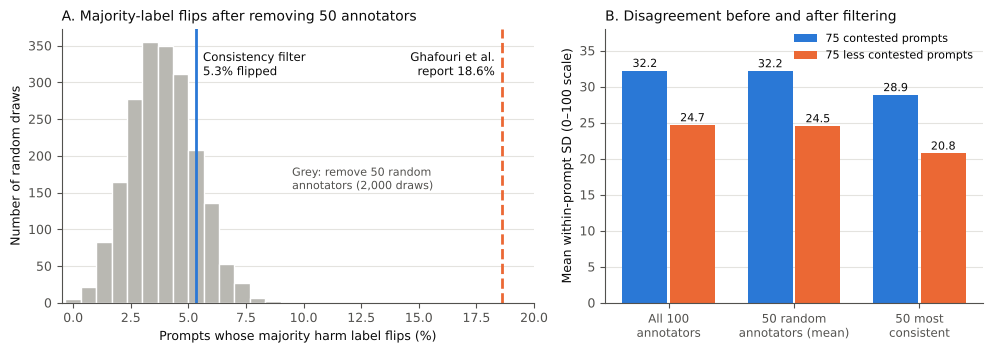

In [ ]:
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt

ROOT = '.'
a = pd.read_csv(f'{ROOT}/data/annotations.csv'); p = pd.read_csv(f'{ROOT}/data/prompts.csv')
R = a[[f'Rating_{q}' for q in p.Question_Index]].values.astype(float)
IR = np.load('outputs/IR.npy')
nA = R.shape[0]
std_p = np.nanstd(R, 0, ddof=1); cont = std_p > np.median(std_p)
def harmful(M): return (M > 50).sum(0) / (~np.isnan(M)).sum(0) > 0.5
base = harmful(R)
keep = np.zeros(nA, bool); keep[np.argsort(IR)[:50]] = True
obs_flip = (harmful(R[keep]) != base).mean() * 100
rng = np.random.default_rng(42)
flips, cstd, ustd = [], [], []
for _ in range(2000):
    k = np.zeros(nA, bool); k[rng.choice(nA, 50, replace=False)] = True
    M = R[k]
    flips.append((harmful(M) != base).mean() * 100)
    cstd.append(np.nanstd(M[:, cont], 0, ddof=1).mean()); ustd.append(np.nanstd(M[:, ~cont], 0, ddof=1).mean())
flips = np.array(flips)

INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#b9b8b2'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1.25, 1]})

# Panel A: flip rate vs random removal
bins = np.arange(-0.333, 20, 0.6667)
ax1.hist(flips, bins=bins, color=GREY, edgecolor='white', linewidth=1)
ymax = ax1.get_ylim()[1]
ax1.axvline(obs_flip, color=BLUE, lw=2)
ax1.text(obs_flip + 0.3, ymax * 0.92, f'Consistency filter\n{obs_flip:.1f}% flipped', color=INK, fontsize=8.5, va='top')
ax1.axvline(18.6, color=ORANGE, lw=2, ls='--')
ax1.text(18.3, ymax * 0.92, 'Ghafouri et al.\nreport 18.6%', color=INK, fontsize=8.5, va='top', ha='right')
ax1.text(9.5, ymax * 0.45, 'Grey: remove 50 random\nannotators (2,000 draws)', color=MUTED, fontsize=8, ha='left', va='center')
ax1.set_xlim(-0.5, 20); ax1.set_xlabel('Prompts whose majority harm label flips (%)')
ax1.set_ylabel('Number of random draws')
ax1.set_title('A. Majority-label flips after removing 50 annotators', loc='left', fontsize=10, color=INK)

# Panel B: disagreement
groups = ['All 100\nannotators', '50 random\nannotators (mean)', '50 most\nconsistent']
c_vals = [np.nanstd(R[:, cont], 0, ddof=1).mean(), np.mean(cstd), np.nanstd(R[keep][:, cont], 0, ddof=1).mean()]
u_vals = [np.nanstd(R[:, ~cont], 0, ddof=1).mean(), np.mean(ustd), np.nanstd(R[keep][:, ~cont], 0, ddof=1).mean()]
x = np.arange(3); w = 0.36
b1 = ax2.bar(x - w / 2 - 0.01, c_vals, w, color=BLUE, label='75 contested prompts')
b2 = ax2.bar(x + w / 2 + 0.01, u_vals, w, color=ORANGE, label='75 less contested prompts')
for bars in (b1, b2):
    for b in bars:
        ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f'{b.get_height():.1f}', ha='center', fontsize=8, color=INK)
ax2.set_xticks(x); ax2.set_xticklabels(groups, fontsize=8.5)
ax2.set_ylabel('Mean within-prompt SD (0–100 scale)'); ax2.set_ylim(0, 38)
ax2.legend(frameon=False, fontsize=8, loc='upper right', bbox_to_anchor=(1, 1.02))
ax2.set_title('B. Disagreement before and after filtering', loc='left', fontsize=10, color=INK)
for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('outputs/fig5_consistency.png', dpi=200)
print(obs_flip, flips.mean(), c_vals, u_vals)